### **EDA for Salary 2019 EUR dataset**

## Download dataset from Kaggle

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("parulpandey/2020-it-salary-survey-for-eu-region")

print("Path to dataset files:", path)

100%|██████████| 85.0k/85.0k [00:00<00:00, 463kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/parulpandey/2020-it-salary-survey-for-eu-region/versions/2


In [2]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
import numpy as np

## Load dataset

In [3]:
path_files = "/root/.cache/kagglehub/datasets/parulpandey/2020-it-salary-survey-for-eu-region/versions/2/"
df = pd.read_csv(path_files+'T Salary Survey EU 2019.csv')

## Fix column names

In [4]:
def clean_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        new_col = col.lower().replace(' ', '_').replace('__','_').replace('(', '').replace(')', '').replace('.', '').replace('/', '_').replace('__', '_')
        new_cols.append(new_col)
    df.columns = new_cols
    return df

df = clean_col_names(df)
print("New column names:")
print(df.columns)

New column names:
Index(['zeitstempel', 'age', 'gender', 'city', 'seniority_level',
       'position_without_seniority', 'years_of_experience',
       'your_main_technology__programming_language',
       'yearly_brutto_salary_without_bonus_and_stocks', 'yearly_bonus',
       'yearly_stocks',
       'yearly_brutto_salary_without_bonus_and_stocks_one_year_ago_only_answer_if_staying_in_same_country',
       'yearly_bonus_one_year_ago_only_answer_if_staying_in_same_country',
       'yearly_stocks_one_year_ago_only_answer_if_staying_in_same_country',
       'number_of_vacation_days', 'number_of_home_office_days_per_month',
       'main_language_at_work', 'company_name_', 'company_size',
       'company_type', 'сontract_duration', 'company_business_sector', '0'],
      dtype='object')


### **Preliminry EDA analysis - missing values, data types, summary statistics, outliers, correlations between features, target distributions**

In [5]:
print("First 5 rows of the dataset:")
display(df.head())

print("\nDataFrame Info (data types and non-null counts):")
display(df.info())

print("\nDescriptive statistics:")
display(df.describe(include='all'))

First 5 rows of the dataset:


,zeitstempel,age,gender,city,seniority_level,position_without_seniority,years_of_experience,your_main_technology__programming_language,yearly_brutto_salary_without_bonus_and_stocks,yearly_bonus,...,yearly_stocks_one_year_ago_only_answer_if_staying_in_same_country,number_of_vacation_days,number_of_home_office_days_per_month,main_language_at_work,company_name_,company_size,company_type,сontract_duration,company_business_sector,0
0,02.12.2019 11:18:26,33.0,Male,Berlin,Senior,Fullstack Developer,13,PHP,64000.0,1000.0,...,NaN,29.0,4.0,English,NaN,50-100,Startup,unlimited,Tourism,NaN
1,02.12.2019 11:18:35,29.0,Male,Berlin,Middle,Backend Developer,3,Python,55000.0,NaN,...,NaN,22.0,4.0,English,NaN,10-50,Product,unlimited,Scientific Activities,NaN
2,02.12.2019 11:18:56,NaN,Male,Berlin,Middle,Mobile Developer,4,Kotlin,70000.0,NaN,...,NaN,27.0,NaN,English,NaN,1000+,Startup,unlimited,NaN,NaN
3,02.12.2019 11:19:08,30.0,Male,Berlin,Senior,Backend Developer,6,PHP,63000.0,NaN,...,NaN,24.0,NaN,English,Auto1,100-1000,Product,unlimited,Transport,NaN
4,02.12.2019 11:19:37,32.0,Male,Berlin,Senior,Embedded Developer,10,C/C++,66000.0,NaN,...,NaN,30.0,0.0,English,Luxoft,50-100,Product,unlimited,Automotive,NaN



DataFrame Info (data types and non-null counts):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 991 entries, 0 to 990
Data columns (total 23 columns):
 #   Column                                                                                             Non-Null Count  Dtype  
---  ------                                                                                             --------------  -----  
 0   zeitstempel                                                                                        991 non-null    object 
 1   age                                                                                                882 non-null    float64
 2   gender                                                                                             991 non-null    object 
 3   city                                                                                               991 non-null    object 
 4   seniority_level                                                         

None


Descriptive statistics:


,zeitstempel,age,gender,city,seniority_level,position_without_seniority,years_of_experience,your_main_technology__programming_language,yearly_brutto_salary_without_bonus_and_stocks,yearly_bonus,...,yearly_stocks_one_year_ago_only_answer_if_staying_in_same_country,number_of_vacation_days,number_of_home_office_days_per_month,main_language_at_work,company_name_,company_size,company_type,сontract_duration,company_business_sector,0
count,991,882.000000,991,991,976,990,991.000000,977,990.000000,530.000000,...,139.000000,931.000000,639.000000,986,256,977,960,962,846,0.0
unique,991,NaN,2,76,6,51,NaN,42,NaN,NaN,...,NaN,NaN,NaN,11,219,5,7,6,52,NaN
top,08.01.2020 22:20:08,NaN,Male,Berlin,Senior,Backend Developer,NaN,Python,NaN,NaN,...,NaN,NaN,NaN,English,Zalando,100-1000,Product,unlimited,Сommerce,NaN
freq,1,NaN,838,430,587,253,NaN,205,NaN,NaN,...,NaN,NaN,NaN,753,7,366,619,851,205,NaN
mean,NaN,32.416100,NaN,NaN,NaN,NaN,8.529768,NaN,72562.212121,7857.169811,...,8204.476331,27.924812,6.462050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,5.262496,NaN,NaN,NaN,NaN,5.036320,NaN,23947.379182,10320.628344,...,45224.397374,4.482911,15.384601,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,20.000000,NaN,NaN,NaN,NaN,0.000000,NaN,6000.000000,0.000000,...,0.000000,4.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,29.000000,NaN,NaN,NaN,NaN,5.000000,NaN,60000.000000,300.000000,...,0.000000,26.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,32.000000,NaN,NaN,NaN,NaN,8.000000,NaN,70000.000000,5000.000000,...,0.100000,28.000000,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,35.000000,NaN,NaN,NaN,NaN,11.000000,NaN,80000.000000,10000.000000,...,3000.000000,30.000000,7.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Percentage missing values in each column

In [6]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percentage': missing_percentage})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Percentage', ascending=False))

,Missing Count,Missing Percentage
0,991,100.000000
yearly_stocks_one_year_ago_only_answer_if_staying_in_same_country,852,85.973764
yearly_stocks,788,79.515641
company_name_,735,74.167508
yearly_bonus_one_year_ago_only_answer_if_staying_in_same_country,734,74.066599
yearly_bonus,461,46.518668
yearly_brutto_salary_without_bonus_and_stocks_one_year_ago_only_answer_if_staying_in_same_country,388,39.152371
number_of_home_office_days_per_month,352,35.519677
company_business_sector,145,14.631685
age,109,10.998991


## Correlations between numerical columns

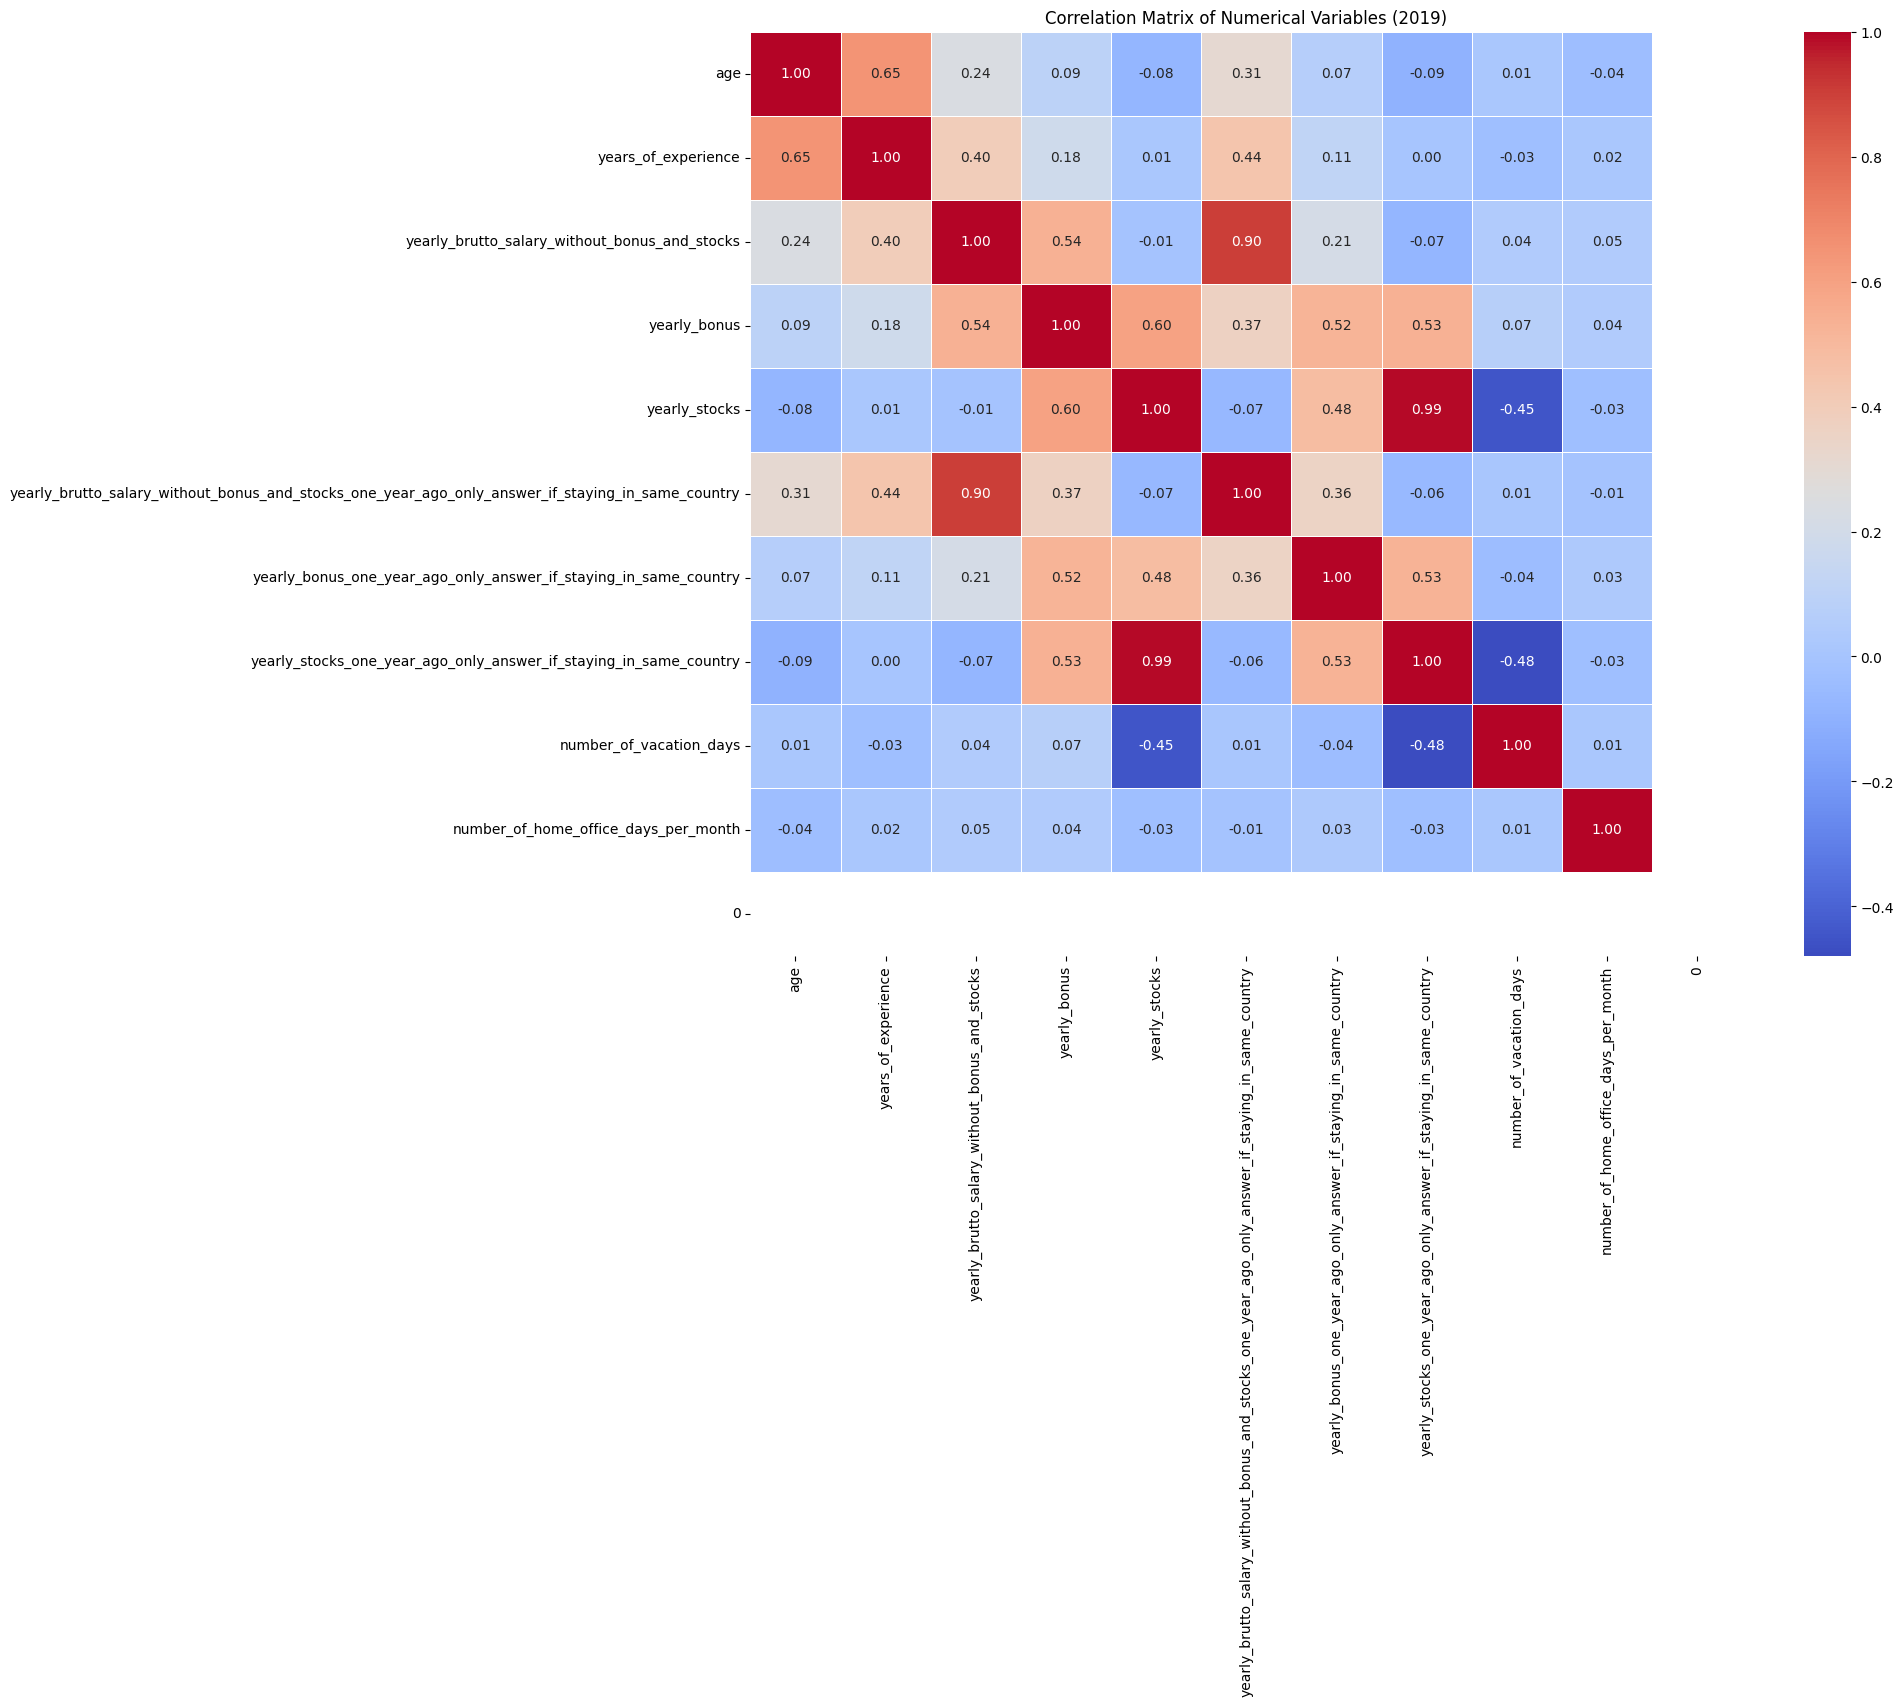

In [7]:
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Numerical Variables (2019)')
plt.show()

## Yearly Brutto Salary Distribution by Company Type

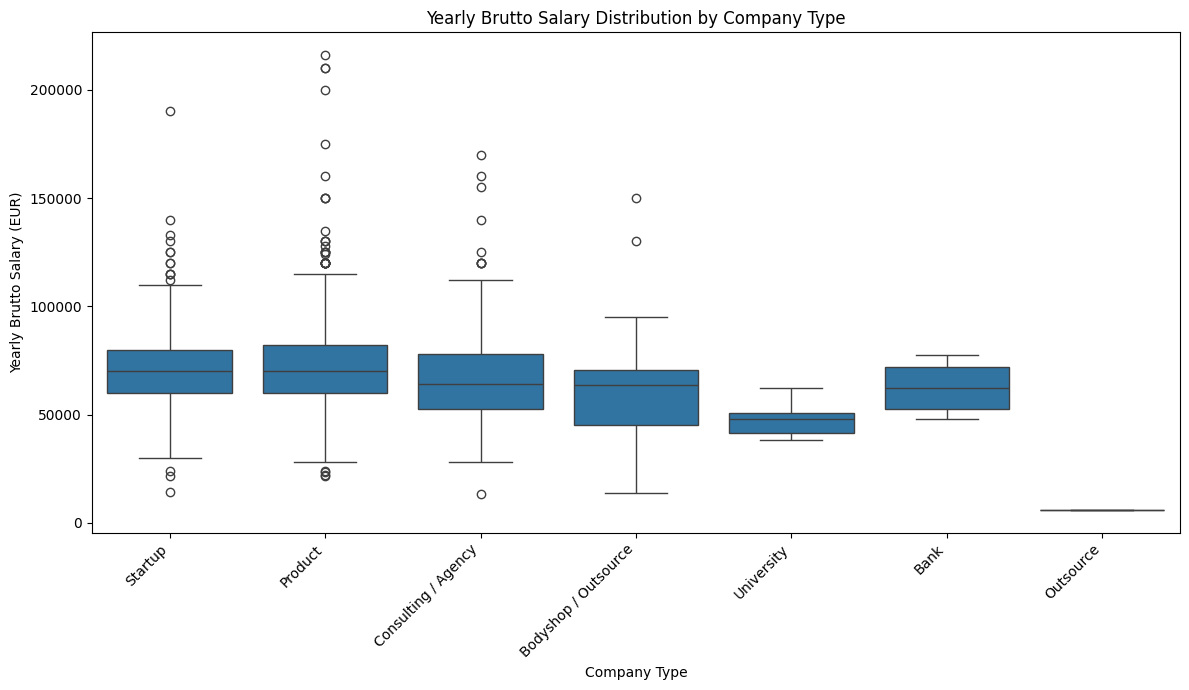

In [9]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='company_type', y='yearly_brutto_salary_without_bonus_and_stocks', \
            data=df.dropna(subset=['company_type', 'yearly_brutto_salary_without_bonus_and_stocks']))
plt.title('Yearly Brutto Salary Distribution by Company Type')
plt.xlabel('Company Type')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Yearly Brutto Salary and Years of Experience

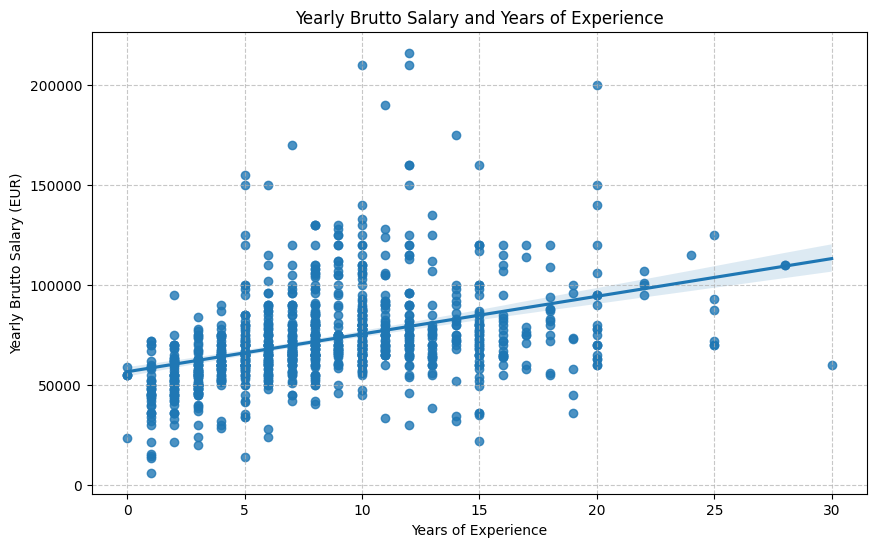

In [10]:
plt.figure(figsize=(10, 6))
sns.regplot(x='years_of_experience', y='yearly_brutto_salary_without_bonus_and_stocks', \
            data=df.dropna(subset=['years_of_experience', 'yearly_brutto_salary_without_bonus_and_stocks']))
plt.title('Yearly Brutto Salary and Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## Create a mapping from city to country

In [11]:
city_to_country = {
    'Berlin': 'Germany',
    'Munich': 'Germany',
    'Amsterdam': 'Netherlands',
    'Frankfurt': 'Germany',
    'Hamburg': 'Germany',
    'Cologne': 'Germany',
    'Stuttgart': 'Germany',
    'Moscow': 'Russia',
    'Düsseldorf': 'Germany',
    'Kyiv': 'Ukraine',
    'London': 'United Kingdom',
    'Warsaw': 'Poland',
    'Zurich': 'Switzerland',
    'Vienna': 'Austria',
    'Prague': 'Czech Republic',
    'Barcelona': 'Spain',
    'Paris': 'France',
    'Lisbon': 'Portugal',
    'Remote': 'Remote'
}

df['country'] = df['city'].map(city_to_country).fillna('UNKNOWN')

print('Number of unique countries:', df['country'].nunique())
print('Top 10 countries by count:')
display(df['country'].value_counts().head(10))

Number of unique countries: 11
Top 10 countries by count:


,count
country,
Germany,795
Netherlands,80
UNKNOWN,76
Russia,11
Ukraine,9
Poland,5
United Kingdom,5
Switzerland,4
Austria,3


## Yearly brutto salary vs. country

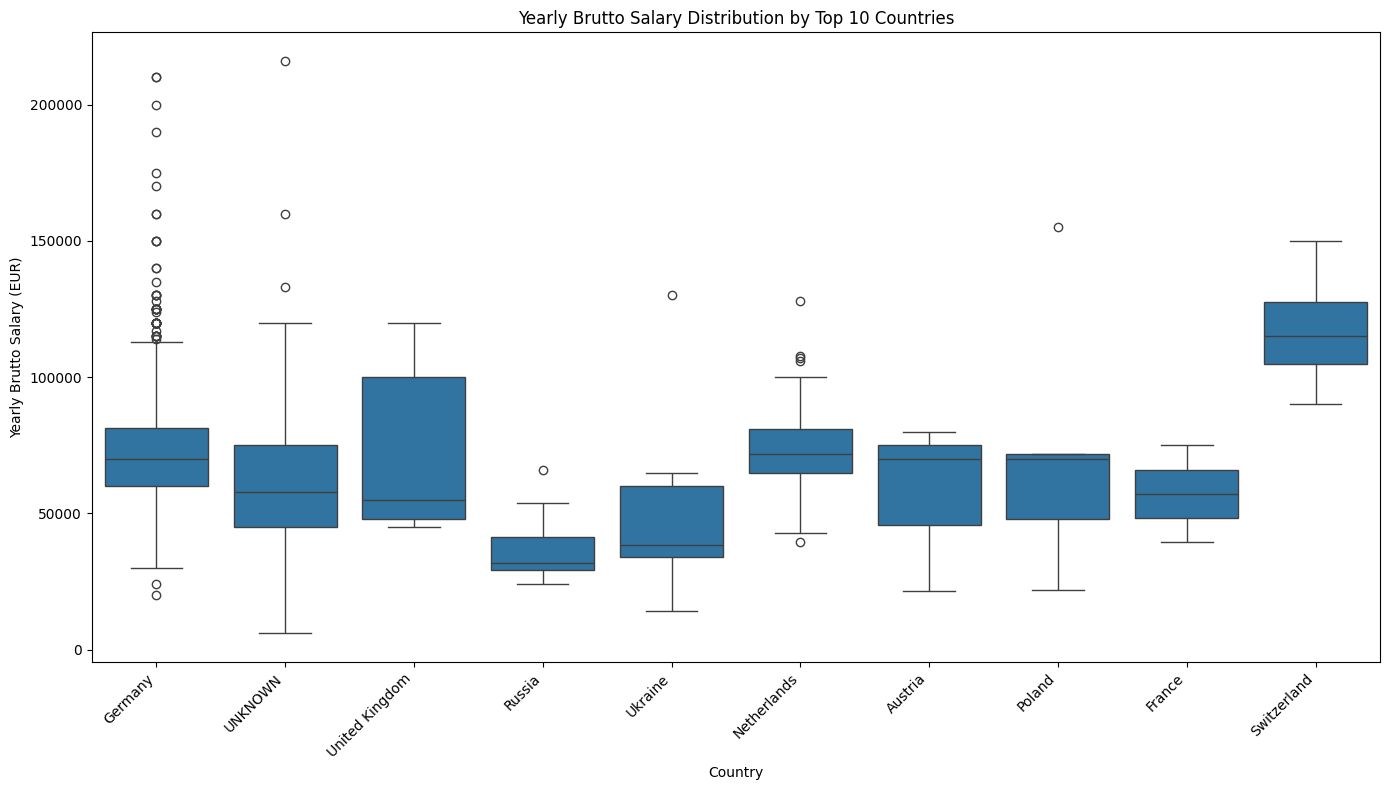

In [12]:
top_countries = df['country'].value_counts().head(10).index
df_top_countries = df[df['country'].isin(top_countries)]

plt.figure(figsize=(14, 8))
sns.boxplot(x='country', y='yearly_brutto_salary_without_bonus_and_stocks', data=df_top_countries.dropna(subset=['country', 'yearly_brutto_salary_without_bonus_and_stocks']))
plt.title('Yearly Brutto Salary Distribution by Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Salary distribution based on gender

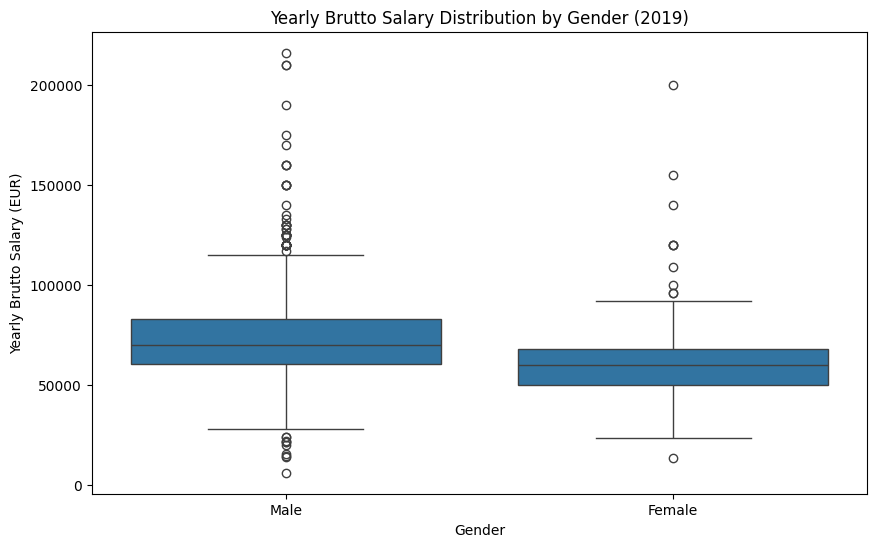

In [13]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='gender', y='yearly_brutto_salary_without_bonus_and_stocks', data=df.dropna(subset=['gender', 'yearly_brutto_salary_without_bonus_and_stocks']))
plt.title('Yearly Brutto Salary Distribution by Gender (2019)')
plt.xlabel('Gender')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.show()

#####################################################################

## Preprocessing before ML

## Salary Distribution

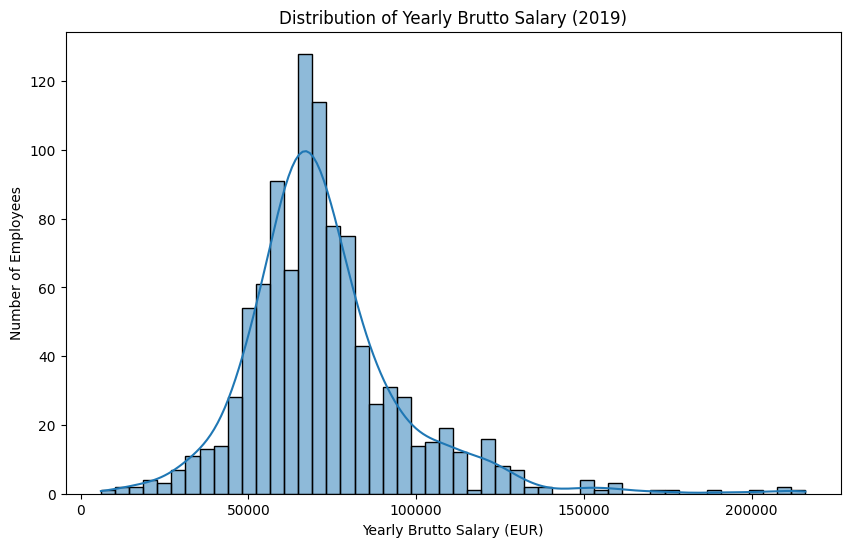

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(df['yearly_brutto_salary_without_bonus_and_stocks'].dropna(), bins=50, kde=True)
plt.title('Distribution of Yearly Brutto Salary (2019)')
plt.xlabel('Yearly Brutto Salary (EUR)')
plt.ylabel('Number of Employees')
plt.show()

### Age Distribution


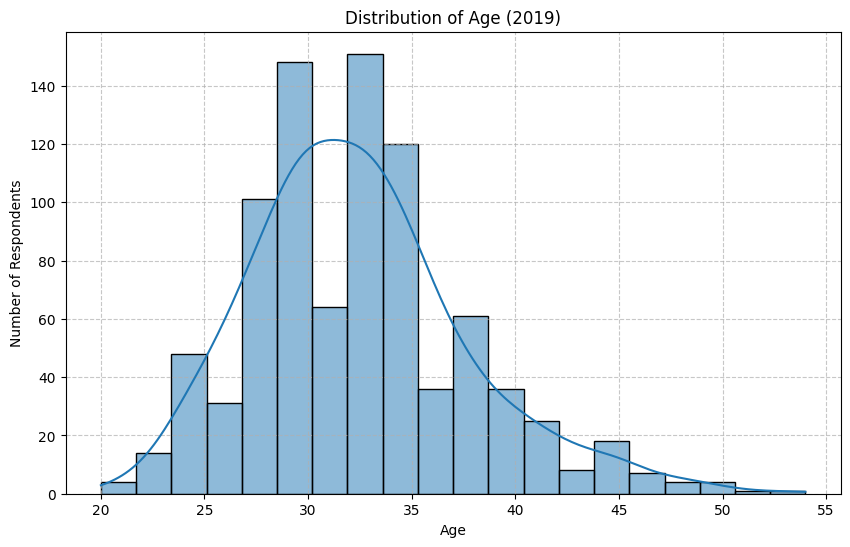

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Distribution of Age (2019)')
plt.xlabel('Age')
plt.ylabel('Number of Respondents')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Ordinal Encoding for 'seniority_level'

In [16]:
seniority_order = [
    'Junior',
    'Middle',
    'Senior',
    'Lead',
    'Head',
    'Principal'
]

encoder = OrdinalEncoder(categories=[seniority_order], handle_unknown='use_encoded_value', unknown_value=-1)

df['seniority_level_encoded'] = encoder.fit_transform(df[['seniority_level']])

## Yearly brutto salary vs. seniority level

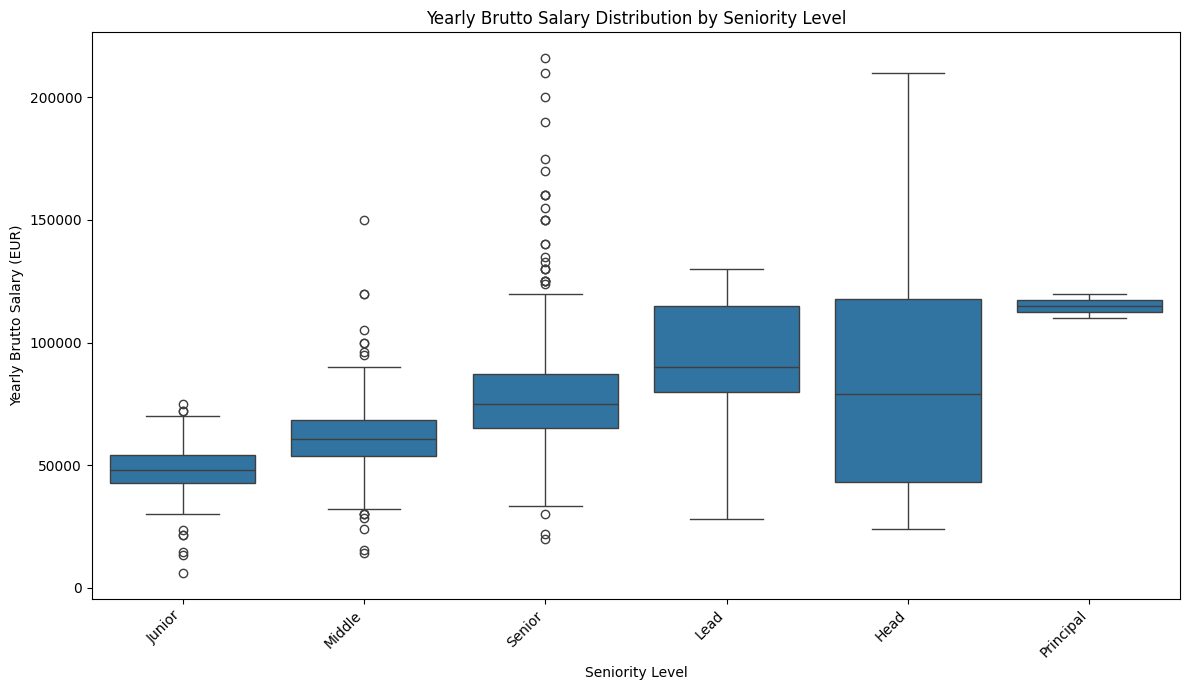

In [17]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='seniority_level', y='yearly_brutto_salary_without_bonus_and_stocks', \
            data=df.dropna(subset=['seniority_level', 'yearly_brutto_salary_without_bonus_and_stocks']),\
            order=seniority_order)
plt.title('Yearly Brutto Salary Distribution by Seniority Level')
plt.xlabel('Seniority Level')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Yearly brutto salary vs. company size

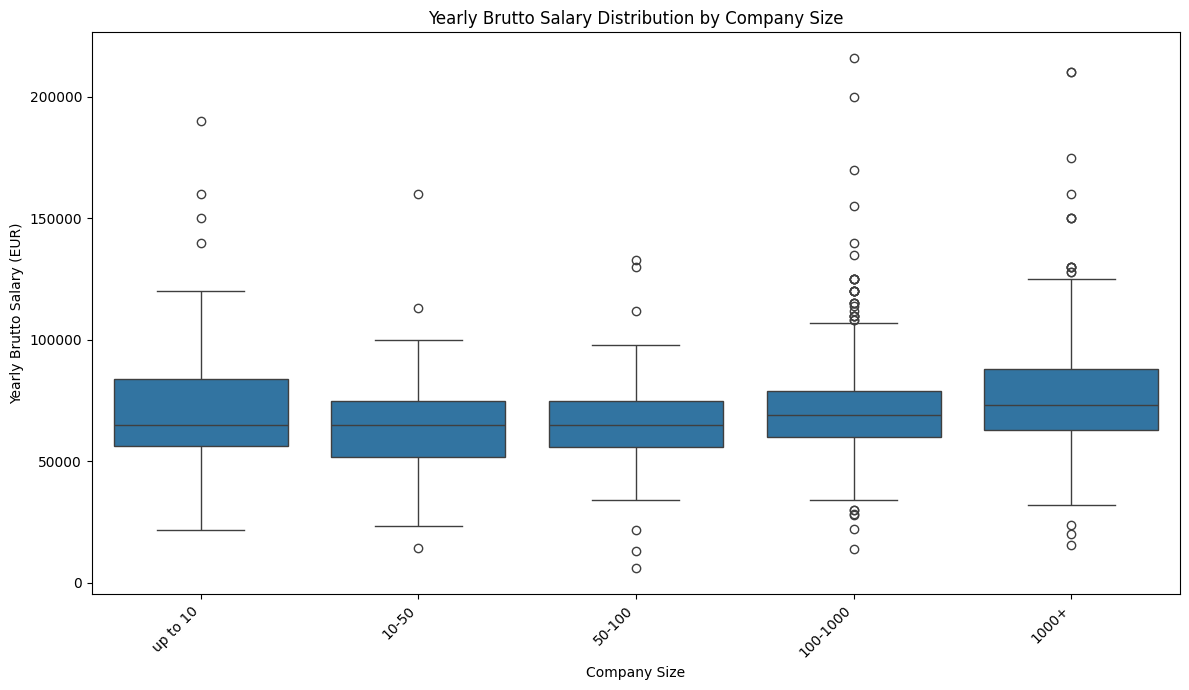

In [18]:
company_size = [
    'up to 10',
    '10-50',
    '50-100',
    '100-1000',
    '1000+'
]
encoder = OrdinalEncoder(categories=[company_size], handle_unknown='use_encoded_value', unknown_value=-1)

df['company_size_encoded'] = encoder.fit_transform(df[['company_size']])

plt.figure(figsize=(12, 7))
sns.boxplot(x='company_size', y='yearly_brutto_salary_without_bonus_and_stocks',
            data=df.dropna(subset=['company_size_encoded', 'yearly_brutto_salary_without_bonus_and_stocks']),
            order=company_size)
plt.title('Yearly Brutto Salary Distribution by Company Size')
plt.xlabel('Company Size')
plt.ylabel('Yearly Brutto Salary (EUR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### One-Hot Encoding for 'gender'

In [19]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

gender_encoded = encoder.fit_transform(df[['gender']])

gender_df = pd.DataFrame(gender_encoded, columns=encoder.get_feature_names_out(['gender']))

df['gender_Female'] = gender_df['gender_Female']
df['gender_Male'] = gender_df['gender_Male']

df.head()


,zeitstempel,age,gender,city,seniority_level,position_without_seniority,years_of_experience,your_main_technology__programming_language,yearly_brutto_salary_without_bonus_and_stocks,yearly_bonus,...,company_size,company_type,сontract_duration,company_business_sector,0,country,seniority_level_encoded,company_size_encoded,gender_Female,gender_Male
0,02.12.2019 11:18:26,33.0,Male,Berlin,Senior,Fullstack Developer,13,PHP,64000.0,1000.0,...,50-100,Startup,unlimited,Tourism,NaN,Germany,2.0,2.0,0.0,1.0
1,02.12.2019 11:18:35,29.0,Male,Berlin,Middle,Backend Developer,3,Python,55000.0,NaN,...,10-50,Product,unlimited,Scientific Activities,NaN,Germany,1.0,1.0,0.0,1.0
2,02.12.2019 11:18:56,NaN,Male,Berlin,Middle,Mobile Developer,4,Kotlin,70000.0,NaN,...,1000+,Startup,unlimited,NaN,NaN,Germany,1.0,4.0,0.0,1.0
3,02.12.2019 11:19:08,30.0,Male,Berlin,Senior,Backend Developer,6,PHP,63000.0,NaN,...,100-1000,Product,unlimited,Transport,NaN,Germany,2.0,3.0,0.0,1.0
4,02.12.2019 11:19:37,32.0,Male,Berlin,Senior,Embedded Developer,10,C/C++,66000.0,NaN,...,50-100,Product,unlimited,Automotive,NaN,Germany,2.0,2.0,0.0,1.0


### Dropping Columns with High Percentage of Missing Values

In [20]:
perc = 30
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

columns_to_drop = missing_percentage[missing_percentage >= perc].index.tolist()

if columns_to_drop:
    df.drop(columns=columns_to_drop, inplace=True)

print("\nMissing values after dropping high-percentage missing columns:")
display(df.isnull().sum()[df.isnull().sum() > 0])


Missing values after dropping high-percentage missing columns:


,0
age,109
seniority_level,15
position_without_seniority,1
your_main_technology__programming_language,14
yearly_brutto_salary_without_bonus_and_stocks,1
number_of_vacation_days,60
main_language_at_work,5
company_size,14
company_type,31
сontract_duration,29


### Part 2 - Four distinct predictive or analytical questions

### 1. Calculating P(Age | Salary) using binning

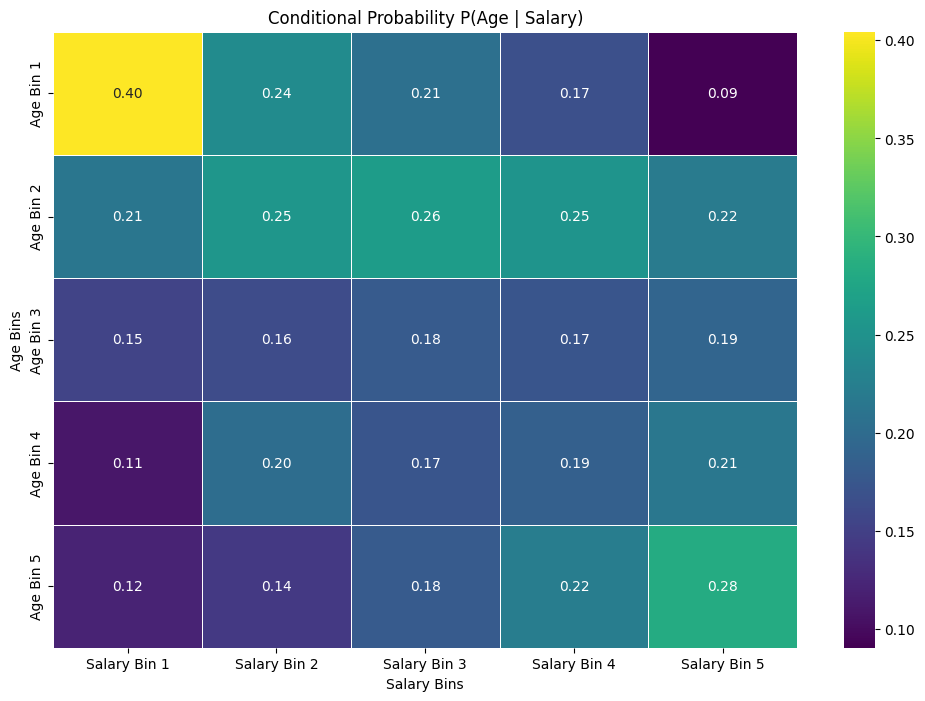

In [21]:
df_prob = df.dropna(subset=['age', 'yearly_brutto_salary_without_bonus_and_stocks']).copy()

df_prob['salary_bins'] = pd.qcut(df_prob['yearly_brutto_salary_without_bonus_and_stocks'], q=5, precision=0, duplicates='drop',
                                 labels=[f'Salary Bin {i+1}' for i in range(5)])

df_prob['age_bins'] = pd.qcut(df_prob['age'], q=5, precision=0, duplicates='drop',
                             labels=[f'Age Bin {i+1}' for i in range(5)])

joint_distribution = pd.crosstab(df_prob['age_bins'], df_prob['salary_bins'], normalize=False)

conditional_probability_age_given_salary = joint_distribution.apply(lambda x: x / x.sum(), axis=0)

plt.figure(figsize=(12, 8))
sns.heatmap(conditional_probability_age_given_salary, annot=True, fmt=".2f", cmap="viridis", linewidths=.5)
plt.title('Conditional Probability P(Age | Salary)')
plt.xlabel('Salary Bins')
plt.ylabel('Age Bins')
plt.show()

As expected, the probability of being young given a low salary (p=0.4) is higher compared to other salary levels. At later stages, the probabilities tend to be smaller, probably due to high variance in seniority and experience.

### 2. Logistic Regression Model to Predict Gender


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

features_logreg = ['yearly_brutto_salary_without_bonus_and_stocks', 'years_of_experience', 'seniority_level_encoded']
target_logreg = 'gender_Male'

data_logreg = df[features_logreg + [target_logreg]].dropna()

X_logreg = data_logreg[features_logreg]
y_logreg = data_logreg[target_logreg]

print(f"Shape of data for Logistic Regression: {data_logreg.shape}")
print(f"Number of samples for training: {len(y_logreg)}")
print(f"Target distribution:\n{y_logreg.value_counts()}")

X_train_logreg, X_test_logreg, y_train_logreg, y_test_logreg = train_test_split(X_logreg, y_logreg, test_size=0.2, random_state=42, stratify=y_logreg)

print(f"\nTraining set size: {len(X_train_logreg)} samples")
print(f"Testing set size: {len(X_test_logreg)} samples")
print(f"Training target distribution:\n{y_train_logreg.value_counts()}")
print(f"Testing target distribution:\n{y_test_logreg.value_counts()}")

Shape of data for Logistic Regression: (990, 4)
Number of samples for training: 990
Target distribution:
gender_Male
1.0    837
0.0    153
Name: count, dtype: int64

Training set size: 792 samples
Testing set size: 198 samples
Training target distribution:
gender_Male
1.0    670
0.0    122
Name: count, dtype: int64
Testing target distribution:
gender_Male
1.0    167
0.0     31
Name: count, dtype: int64


In [23]:
pipeline_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(random_state=42, max_iter=200))
])

pipeline_logreg.fit(X_train_logreg, y_train_logreg)

y_pred_logreg = pipeline_logreg.predict(X_test_logreg)

accuracy = accuracy_score(y_test_logreg, y_pred_logreg)
class_report = classification_report(y_test_logreg, y_pred_logreg)

print(f"\nModel Evaluation on Test Set:")
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(class_report)

print("\nModel Coefficients (after scaling):")
logreg_model = pipeline_logreg.named_steps['logistic_regression']
for feature, coef in zip(features_logreg, logreg_model.coef_[0]):
    print(f"{feature}: {coef:.4f}")


Model Evaluation on Test Set:
Accuracy: 0.83

Classification Report:
              precision    recall  f1-score   support

         0.0       0.29      0.06      0.11        31
         1.0       0.85      0.97      0.91       167

    accuracy                           0.83       198
   macro avg       0.57      0.52      0.51       198
weighted avg       0.76      0.83      0.78       198


Model Coefficients (after scaling):
yearly_brutto_salary_without_bonus_and_stocks: 0.3192
years_of_experience: 0.2916
seniority_level_encoded: 0.5228


As expected, there is a significant different in gender when looking at seniority level, salary, and years of experience. Due to class imbalance, the model do not perform well in predicting the smaller class (females).

### 3. Regression Model to predict Salary

In [24]:
features = ['age', 'seniority_level_encoded', 'years_of_experience']
raw_target = 'yearly_brutto_salary_without_bonus_and_stocks'

data_for_model = df[features + [raw_target]].dropna()

y = np.log(data_for_model[raw_target])
X = data_for_model[features]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")


Training set size: 705 samples
Testing set size: 177 samples


In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pipeline_linreg = Pipeline([
    ('scaler', StandardScaler()),
    ('linear_regression', LinearRegression())
])

pipeline_linreg.fit(X_train, y_train)

print("Linear Regression model (with StandardScaler) trained successfully.")

y_pred = pipeline_linreg.predict(X_test)

mse_log = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nModel Evaluation on Test Set (Log Transformed Salary):")
print(f"Mean Squared Error (MSE) on log scale: {mse_log:.4f}")
print(f"R-squared (R2): {r2:.2f}")

print("\nModel Coefficients (after scaling, for log-transformed salary):")
linreg_model = pipeline_linreg.named_steps['linear_regression']
for feature, coef in zip(features, linreg_model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {linreg_model.intercept_:.4f}")

Linear Regression model (with StandardScaler) trained successfully.

Model Evaluation on Test Set (Log Transformed Salary):
Mean Squared Error (MSE) on log scale: 0.0926
R-squared (R2): 0.28

Model Coefficients (after scaling, for log-transformed salary):
age: 0.0166
seniority_level_encoded: 0.1022
years_of_experience: 0.0808
Intercept: 11.1120


The percentage of variance explained is 28%, which means that the features do not largely explain the target variable (salary). This might be due to the fact that gender was not included as a feature.

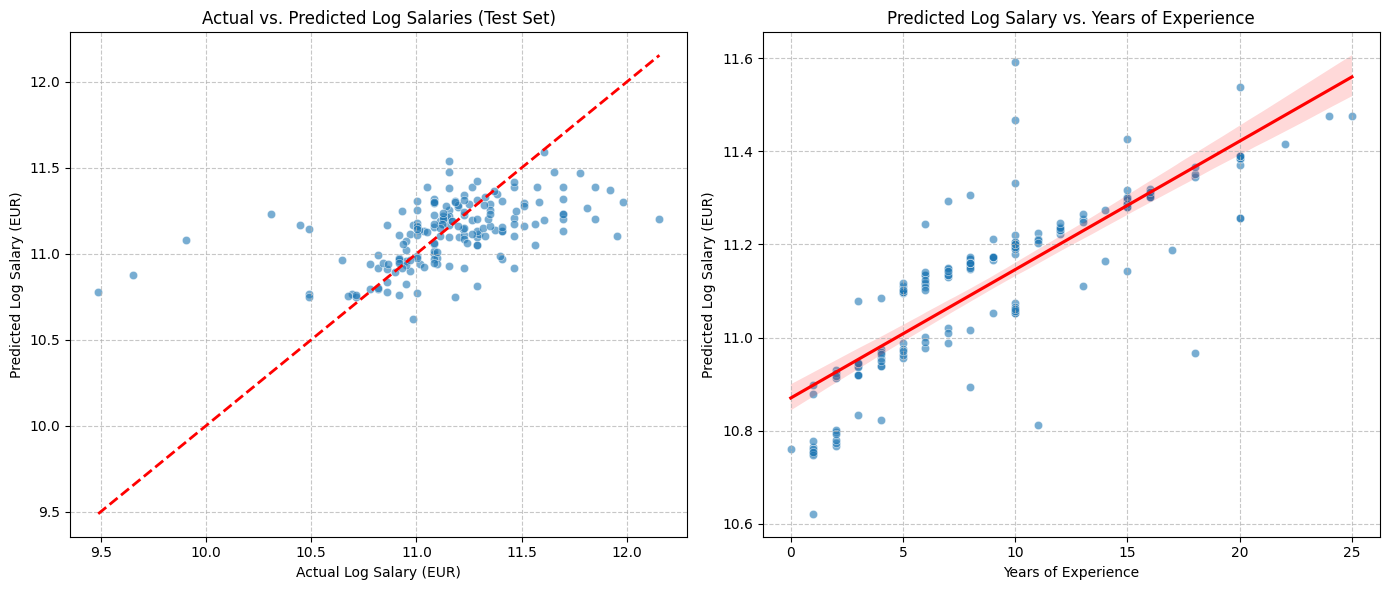

In [130]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted Log Salaries (Test Set)')
plt.xlabel('Actual Log Salary (EUR)')
plt.ylabel('Predicted Log Salary (EUR)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
sns.scatterplot(x=X_test['years_of_experience'], y=y_pred, alpha=0.6)
sns.regplot(x=X_test['years_of_experience'], y=y_pred, scatter=False, color='red')
plt.title('Predicted Log Salary vs. Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Predicted Log Salary (EUR)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### 4. Estimating Distribution for Salary


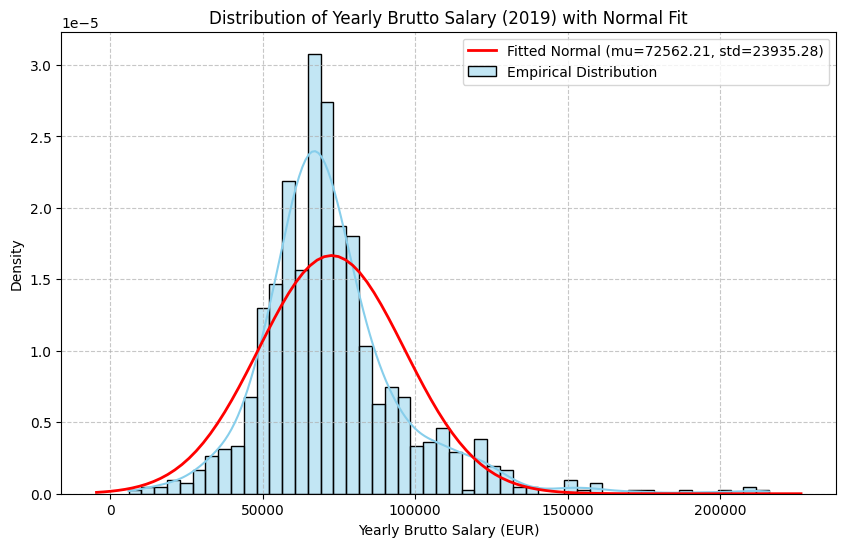

In [123]:
from scipy.stats import norm

salary_data = df['yearly_brutto_salary_without_bonus_and_stocks'].dropna()

mu, std = norm.fit(salary_data)

plt.figure(figsize=(10, 6))
sns.histplot(salary_data, bins=50, kde=True, stat='density', color='skyblue', label='Empirical Distribution')

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'r', linewidth=2, label=f'Fitted Normal (mu={mu:.2f}, std={std:.2f})')

plt.title('Distribution of Yearly Brutto Salary (2019) with Normal Fit')
plt.xlabel('Yearly Brutto Salary (EUR)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()